# EDA: рентгеновские изображения литых деталей
Исходные данные читаются без изменений. Все результаты рассчитаны заново, без использования прежних EDA-таблиц. Серия съёмки и независимая физическая деталь — разные понятия.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib, json, re, warnings
import numpy as np
import pandas as pd
from PIL import Image
from scipy.fft import dctn
from scipy.io import loadmat
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 12)
ROOT = Path('/Casting')
if not ROOT.is_dir():
    ROOT = Path.cwd() / 'Castings'
    print('Основной путь /Casting отсутствует; локальный путь:', ROOT)
assert ROOT.is_dir(), 'Каталог датасета не найден'
PROJECT = ROOT.parent
files = sorted(p for p in ROOT.rglob('*') if p.is_file())
paths = [p for p in files if p.suffix.lower() in {'.png','.jpg','.jpeg','.tif','.tiff','.bmp','.pgm'}]
series_dirs = sorted({p.parent for p in paths})
readmes = {d.name: '\n'.join(p.read_text(errors='replace') for p in sorted(d.glob('*readme*'))) for d in series_dirs}
print('Каталоги серий:', len(series_dirs), '| Файлы:', len(files))
display(pd.DataFrame(Counter(p.suffix.lower() or '[без расширения]' for p in files).items(), columns=['Расширение','Файлов']))
print('Формат координат подтверждён локальным MATLAB-примером:')
demo = ROOT / 'C0002/display_demo.m'
print(demo.read_text() if demo.exists() else 'MATLAB-пример отсутствует; проверьте соглашение координат')


Основной путь /Casting отсутствует; локальный путь: C:\Users\husae\OneDrive\Desktop\Обучение\diplom\Castings
Каталоги серий: 87 | Файлы: 4151
Формат координат подтверждён локальным MATLAB-примером:
% This example display the defects of image 16
GT = load('ground_truth.txt');
I = imread('C0002_0016.png');
imshow(I,[])
hold on
ii = find(GT(:,1) == 16);
n = length(ii);
for i = 1:n
    t = GT(ii(i),2:end);
    plot(t([1 2 2 1 1]),t([3 3 4 4  3]),'r');
end



,Расширение,Файлов
0,.mat,37
1,.png,3981
2,.txt,130
3,.m,1
4,[без расширения],1
5,.txt;,1


## 1. Изображения и качество файлов
SHA-256 файлов проверяет байтовую идентичность. Отдельный хеш декодированных пикселей включает размерность и тип массива: различия упаковки PNG не скрывают точные копии.

In [2]:
rows=[]; thumbnails={}; errors=[]
for p in paths:
    r=dict(image_id=p.stem, series=p.parent.name, relative=str(p.relative_to(ROOT)), bytes=p.stat().st_size,
           file_hash=hashlib.sha256(p.read_bytes()).hexdigest(), damaged=False)
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            im.load(); a=np.asarray(im)
            r.update(width=im.width,height=im.height,mode=im.mode,channels=len(im.getbands()),format=im.format,
                     dtype=str(a.dtype),resolution=f'{im.width}×{im.height}')
            header=p.read_bytes()[:26]
            r['bits']=int(header[24]) if header[:8]==b'\x89PNG\r\n\x1a\n' else a.dtype.itemsize*8
            r['pixel_hash']=hashlib.sha256(str((a.shape,str(a.dtype))).encode()+a.tobytes()).hexdigest()
            gray=a.astype(np.float32) if a.ndim==2 else a[...,:3].mean(axis=2).astype(np.float32)
            thumb=np.asarray(Image.fromarray(gray).resize((32,32),Image.Resampling.BOX))
            v=dctn(thumb,norm='ortho')[:8,:8].ravel()[1:]
            r['phash']=sum(int(b)<<i for i,b in enumerate(v>np.median(v)))
            thumbnails[p.stem]=thumb
    except Exception as e:
        r['damaged']=True; errors.append((str(p.relative_to(ROOT)),str(e)))
    rows.append(r)
images=pd.DataFrame(rows); good=images.loc[~images.damaged].copy()
print('Изображений:',len(images),'| Повреждено:',int(images.damaged.sum()))
display(good.groupby(['format','mode','channels','bits'],dropna=False).size().rename('Изображений').reset_index())
display(good[['width','height','bytes']].agg(['min','median','max']).round(1))
print('Уникальных разрешений:',good.resolution.nunique())
display(good.resolution.value_counts().head(8).rename_axis('Разрешение').to_frame('Изображений'))
def duplicate_stats(column):
    groups=[g for _,g in good.groupby(column) if len(g)>1]
    return dict(groups=len(groups),members=sum(len(g) for g in groups),extra=sum(len(g)-1 for g in groups),
                unique=good[column].nunique(),cross_series=sum(g.series.nunique()>1 for g in groups))
exact={k:duplicate_stats(k) for k in ['file_hash','pixel_hash']}
display(pd.DataFrame(exact).T.rename(columns={'groups':'Групп','members':'Участников','extra':'Лишних копий','unique':'Уникальных','cross_series':'Межсерийных групп'}))
if errors: display(pd.DataFrame(errors,columns=['Файл','Ошибка']))


Изображений: 3981 | Повреждено: 0
Уникальных разрешений: 85


,format,mode,channels,bits,Изображений
0,PNG,I;16,1,16,21
1,PNG,L,1,8,3960


,width,height,bytes
min,200.0,135.0,3871.0
median,768.0,572.0,153371.0
max,1992.0,1992.0,1301323.0


,Изображений
Разрешение,
768×572,1589
1000×1000,1117
256×256,534
768×574,514
1992×1992,33
1024×1024,32
301×141,30
350×151,10


,Групп,Участников,Лишних копий,Уникальных,Межсерийных групп
file_hash,10,20,10,3971,0
pixel_hash,233,478,245,3736,223


## 2. Аннотации и наблюдаемые дефекты
Основной источник — `ground_truth.txt`; единственный `Xgdxannotate(...)` используется при отсутствии основного. Версии TXT и MATLAB проверяются отдельно и не суммируются. Координаты MATLAB переводятся в нулевую систему вычитанием 1; граничные нарушения проверяются также при альтернативной непрерывной границе W/H.

Задача: детекция прямоугольников; типы дефектов и маски не заданы.
Источников: 37 | Рамок: 3307 | Изображений с рамками: 1031
Без рамок: 2950 — не эквивалентно отсутствию дефектов.
Без основного источника: 2460 | Не перечислены в имеющемся источнике: 490
Нарушений границ W−1/H−1: 6 на 6 изображениях; W/H: 2
Ссылок на отсутствующие изображения: 0 | Ошибок чтения аннотаций: 0
Альтернативных файлов: 44 | Отличаются от основного среди сопоставимых: 11


,series,image_id,x1,x2,y1,y2,valid_continuous
722,C0024,C0024_0027,642.0,768.0,319.0,396.0,True
757,C0029,C0029_0031,287.0,468.0,-1.0,569.0,False
920,C0032,C0032_0011,732.0,768.0,331.0,366.0,True
924,C0033,C0033_0005,750.0,768.0,388.0,420.0,True
928,C0033,C0033_0009,655.0,768.0,319.0,398.0,True
1478,C0045,C0045_0050,-1.0,9.0,57.0,71.0,False


,width,height,relative_area
0.00,2.0,2.0,0.000004
0.25,20.0,18.0,0.001021
0.50,27.0,20.0,0.001311
0.90,56.0,54.0,0.005775
1.00,229.0,565.0,0.277180


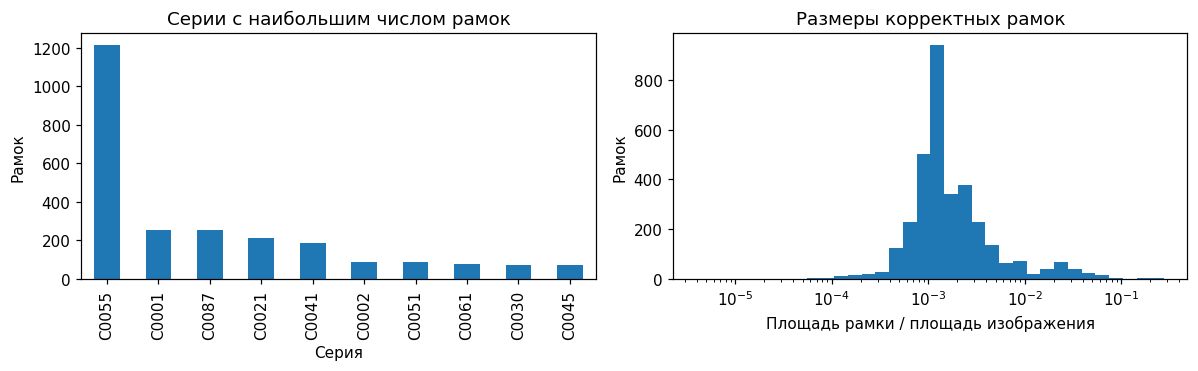

In [3]:
ann=[]; sources={}; alternatives=[]; parse_errors=[]; orphan=[]
lookup=good.set_index('image_id')
for d in series_dirs:
    primary=d/'ground_truth.txt'
    candidates=sorted(d.glob('Xgdxannotate(*'))
    chosen=primary if primary.exists() else (candidates[0] if len(candidates)==1 else None)
    base=None
    if chosen:
        try:
            base=np.loadtxt(chosen,ndmin=2)
            assert base.shape[1]==5 and np.isfinite(base).all()
            sources[d.name]=chosen.name
            for n,row in enumerate(base,1):
                idx,x1,x2,y1,y2=row
                if idx!=int(idx): raise ValueError('Не целочисленный номер кадра')
                iid=f'{d.name}_{int(idx):04d}'
                if iid not in lookup.index:
                    orphan.append((d.name,n,iid)); continue
                im=lookup.loc[iid]; x1,x2,y1,y2=np.array([x1,x2,y1,y2])-1
                positive=x2>x1 and y2>y1
                strict=positive and 0<=x1<x2<=im.width-1 and 0<=y1<y2<=im.height-1
                continuous=positive and 0<=x1<x2<=im.width and 0<=y1<y2<=im.height
                ann.append(dict(series=d.name,image_id=iid,x1=x1,x2=x2,y1=y1,y2=y2,valid=strict,
                                valid_continuous=continuous,relative_area=(x2-x1)*(y2-y1)/(im.width*im.height),
                                width=x2-x1,height=y2-y1))
        except Exception as e: parse_errors.append((str(chosen),str(e)))
    for p in sorted(d.iterdir()):
        if p==chosen or not (p.suffix.lower()=='.mat' or 'ground_truth' in p.name or p.name.startswith('gt') or p.name=='new_gt.txt'): continue
        try:
            if p.suffix.lower()=='.mat':
                arrays={k:v for k,v in loadmat(p).items() if not k.startswith('__')}
                alt=arrays.get('bb'); shape='; '.join(f'{k}:{v.shape}' for k,v in arrays.items())
            else:
                alt=np.loadtxt(p,ndmin=2); shape=str(alt.shape)
            equal=bool(base is not None and alt is not None and base.shape==alt.shape and np.allclose(base,alt,rtol=0,atol=1e-6))
            alternatives.append(dict(series=d.name,file=p.name,shape=shape,comparable=base is not None and alt is not None,equal=equal))
        except Exception as e: parse_errors.append((str(p),str(e)))
boxes=pd.DataFrame(ann); counts=boxes.image_id.value_counts()
images['boxes']=images.image_id.map(counts).fillna(0).astype(int)
images['annotation_file']=images.series.isin(sources)
series=images.groupby('series').agg(images=('image_id','size'),listed_images=('boxes',lambda x:int((x>0).sum())),boxes=('boxes','sum'))
series['annotation_source']=[sources.get(s,'—') for s in series.index]
series['readme_status']=[('без дефектов (README)' if 'unlabeled X-ray images with no defects' in readmes[s] else
                          'с дефектами (README)' if 'unlabeled X-ray images with defects' in readmes[s] else 'не установлен') for s in series.index]
print('Задача: детекция прямоугольников; типы дефектов и маски не заданы.')
print('Источников:',len(sources),'| Рамок:',len(boxes),'| Изображений с рамками:',int((images.boxes>0).sum()))
print('Без рамок:',int((images.boxes==0).sum()),'— не эквивалентно отсутствию дефектов.')
print('Без основного источника:',int((~images.annotation_file).sum()),'| Не перечислены в имеющемся источнике:',int((images.annotation_file & images.boxes.eq(0)).sum()))
print('Нарушений границ W−1/H−1:',int((~boxes.valid).sum()),'на',boxes.loc[~boxes.valid,'image_id'].nunique(),'изображениях; W/H:',int((~boxes.valid_continuous).sum()))
print('Ссылок на отсутствующие изображения:',len(orphan),'| Ошибок чтения аннотаций:',len(parse_errors))
alt_df=pd.DataFrame(alternatives)
print('Альтернативных файлов:',len(alt_df),'| Отличаются от основного среди сопоставимых:',int((alt_df.comparable & ~alt_df.equal).sum()))
display(boxes.loc[~boxes.valid,['series','image_id','x1','x2','y1','y2','valid_continuous']])
display(boxes.loc[boxes.valid,['width','height','relative_area']].quantile([0,.25,.5,.9,1]).round(6))
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
series.boxes.nlargest(10).plot.bar(ax=ax[0],title='Серии с наибольшим числом рамок',ylabel='Рамок',xlabel='Серия')
ax[1].hist(boxes.loc[boxes.valid,'relative_area'],bins=np.geomspace(boxes.loc[boxes.valid,'relative_area'].min(),boxes.loc[boxes.valid,'relative_area'].max(),35))
ax[1].set(xscale='log',xlabel='Площадь рамки / площадь изображения',ylabel='Рамок',title='Размеры корректных рамок')
plt.tight_layout(); plt.show()


## 3. Близкие изображения и межсерийные связи
Полный попарный поиск по 63-битному pHash, расстояние Хэмминга ≤6. Это кандидаты визуального сходства, а не подтверждённые дубликаты. Точные пиксельные совпадения исключены. Связные компоненты сходства не доказывают общую физическую деталь.

In [4]:
records=list(good[['image_id','series','pixel_hash','phash']].itertuples(index=False,name=None))
near=[]; parent=list(range(len(records)))
def find(i):
    while parent[i]!=i:
        parent[i]=parent[parent[i]]; i=parent[i]
    return i
for i,(iid,s,pix,h) in enumerate(records):
    for j in range(i):
        jid,t,q,k=records[j]
        if pix==q: continue
        distance=(int(h)^int(k)).bit_count()
        if distance<=6:
            near.append((iid,jid,s,t,distance)); parent[find(i)]=find(j)
near=pd.DataFrame(near,columns=['a','b','series_a','series_b','distance'])
near_nodes=set(near.a)|set(near.b)
near_components=len({find(i) for i,r in enumerate(records) if r[0] in near_nodes})
cross=near[near.series_a!=near.series_b]
print('Кандидатных пар:',len(near),'| Изображений:',len(near_nodes),'| Компонент:',near_components,'| Межсерийных пар:',len(cross))
display(cross.groupby(['series_a','series_b']).size().nlargest(10).rename('Пар').reset_index())
print('Документированная зависимость C0002 от C0001:')
print('\n'.join(line.strip() for line in readmes.get('C0002','').splitlines() if 'crop' in line.lower()))
print('Доказательство последовательной съёмки C0001:')
print('\n'.join(line.strip() for line in readmes.get('C0001','').splitlines() if 'rotation' in line.lower() or 'manipulator' in line.lower()))

pixel_groups = good.groupby('pixel_hash')
conflicting_pixel_groups = 0
for _, group in pixel_groups:
    if len(group) < 2:
        continue
    signatures = set()
    for iid in group.image_id:
        coords = boxes.loc[boxes.image_id == iid, ['x1','x2','y1','y2']].to_numpy()
        signatures.add(tuple(sorted(tuple(np.round(row, 6)) for row in coords)))
    if len(signatures) > 1:
        conflicting_pixel_groups += 1
print('Групп точных пиксельных копий с различающимися основными рамками:', conflicting_pixel_groups)


Кандидатных пар: 36596 | Изображений: 3338 | Компонент: 276 | Межсерийных пар: 13147
Документированная зависимость C0002 от C0001:
<crops of C0001 with defects>
Доказательство последовательной съёмки C0001:
<rotation each 5 degrees>
[Manipulator position]
The translation and rotation of the manipulator is given in file ManipulatorPosition.txt. Row p of this file has the values of tx, ty, tz, wx, wy and wz for position p, ie for image C0001_p.png
Групп точных пиксельных копий с различающимися основными рамками: 110


,series_a,series_b,Пар
0,C0087,C0085,2906
1,C0086,C0084,2654
2,C0085,C0084,2565
3,C0086,C0085,2565
4,C0067,C0066,443
5,C0050,C0049,280
6,C0051,C0044,192
7,C0048,C0047,188
8,C0087,C0084,173
9,C0087,C0086,173


## 4. Репрезентативные примеры
Красные рамки — геометрически корректные, оранжевые — требующие проверки. Отсутствие рамок не является отрицательной меткой. Яркость нормируется только для отображения.

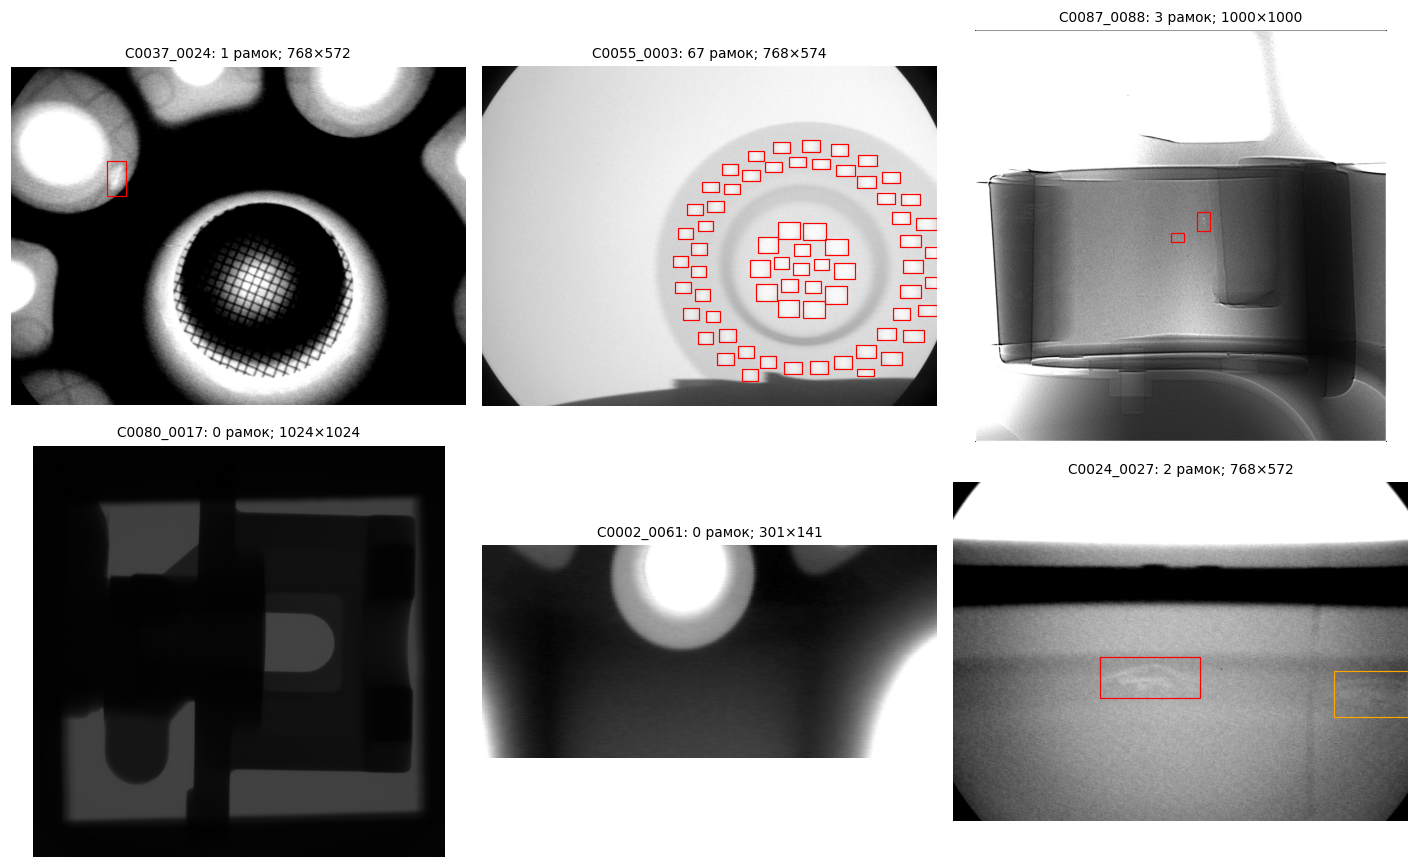

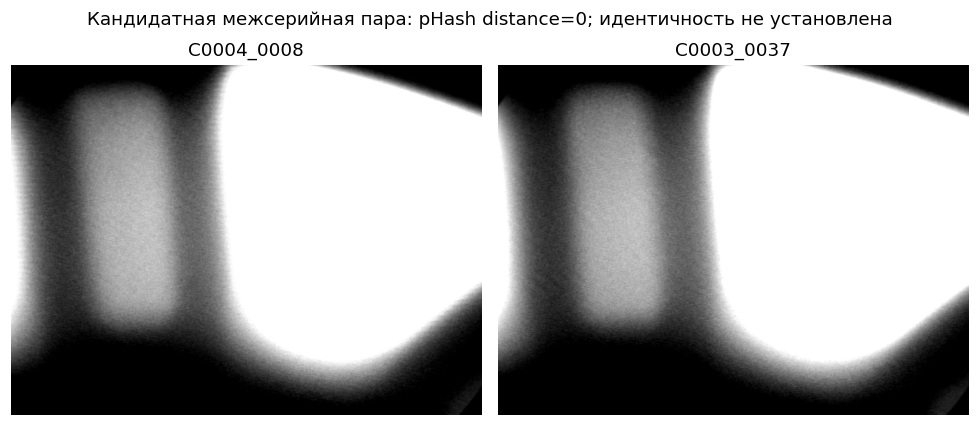

In [5]:
selected=[]
for iid in [images.loc[images.boxes>0].sort_values('boxes').iloc[0].image_id,
            counts.idxmax(), boxes.loc[boxes.valid].sort_values('relative_area').iloc[0].image_id,
            good.loc[good.bits==good.bits.max()].iloc[0].image_id,
            images.loc[images.boxes==0].iloc[0].image_id,
            boxes.loc[~boxes.valid].iloc[0].image_id if (~boxes.valid).any() else images.iloc[-1].image_id]:
    if iid not in selected: selected.append(iid)
fig,axes=plt.subplots(2,3,figsize=(13,8))
for ax,iid in zip(axes.flat,selected):
    r=lookup.loc[iid]
    with Image.open(ROOT/r.relative) as im: a=np.asarray(im)
    ax.imshow(a,cmap='gray'); b=boxes[boxes.image_id==iid]
    for row in b.itertuples(): ax.add_patch(Rectangle((row.x1,row.y1),row.width,row.height,fill=False,color='red' if row.valid else 'orange',linewidth=.8))
    ax.set_title(f'{iid}: {len(b)} рамок; {r.resolution}',fontsize=9); ax.axis('off')
for ax in axes.flat[len(selected):]: ax.axis('off')
plt.tight_layout(); plt.show()
if len(cross):
    example=cross.sort_values(['distance','a','b']).iloc[0]
    fig,axes=plt.subplots(1,2,figsize=(9,4))
    for ax,iid in zip(axes,[example.a,example.b]):
        with Image.open(ROOT/lookup.loc[iid,'relative']) as im: ax.imshow(np.asarray(im),cmap='gray')
        ax.set_title(iid); ax.axis('off')
    fig.suptitle(f'Кандидатная межсерийная пара: pHash distance={example.distance}; идентичность не установлена')
    plt.tight_layout(); plt.show()


## 5. Серии и существующие разбиения
Cxxxx — идентификаторы наборов/последовательностей съёмки по именам и README, а не классы. Полной карты «физическая деталь → серия → кадр» нет. Проверка ниже читает существующие экспорты рядом с исходным набором; ничего не переразбивает.

In [6]:
display(series.rename(columns={'images':'Снимков','listed_images':'С рамками','boxes':'Рамок','annotation_source':'Источник','readme_status':'Статус README'}))
print('Каталоги train/val/test в исходном наборе:',[str(p.relative_to(ROOT)) for p in ROOT.rglob('*') if p.is_dir() and p.name.lower() in {'train','test','val','valid','validation'}])
split_results=[]
for manifest in sorted((PROJECT/'datasets').glob('*/splits.csv')):
    m=pd.read_csv(manifest)
    if not {'image_id','split','included'}.issubset(m.columns): continue
    included=m[m.included.astype(str).str.lower().eq('true')].copy()
    joined=included[['image_id','split']].merge(images[['image_id','series','file_hash','pixel_hash']],on='image_id',how='left',validate='many_to_one')
    missing=int(joined.pixel_hash.isna().sum())
    crossing={key:int((joined.groupby(key).split.nunique()>1).sum()) for key in ['image_id','series','file_hash','pixel_hash']}
    membership=joined.groupby('image_id').split.agg(set).to_dict()
    near_cross=sum(any(x!=y for x in membership.get(r.a,set()) for y in membership.get(r.b,set())) for r in near.itertuples())
    crop_cross=any(x!=y for x in joined.loc[joined.series=='C0001','split'] for y in joined.loc[joined.series=='C0002','split'])
    result=dict(dataset=manifest.parent.name,counts=included.split.value_counts().to_dict(),missing=missing,**crossing,near_pairs=near_cross,crop_cross=crop_cross)
    split_results.append(result)
    print(json.dumps(result,ensure_ascii=False))
    display(included.groupby(['split','annotation_status']).size().rename('Изображений').reset_index() if 'annotation_status' in included else included.split.value_counts().to_frame())
print('Отсутствие найденных пересечений не доказывает независимость физических деталей.')


Каталоги train/val/test в исходном наборе: []
{"dataset": "castings_c114dcf90646", "counts": {"train": 697, "test": 167, "val": 153}, "missing": 0, "image_id": 0, "series": 0, "file_hash": 0, "pixel_hash": 0, "near_pairs": 0, "crop_cross": false}
Отсутствие найденных пересечений не доказывает независимость физических деталей.


,Снимков,С рамками,Рамок,Источник,Статус README
series,,,,,
C0001,72,72,256,ground_truth.txt,не установлен
C0002,90,60,88,ground_truth.txt,не установлен
C0003,37,0,0,—,не установлен
C0004,37,0,0,—,не установлен
C0005,37,0,0,—,не установлен
C0006,37,0,0,—,не установлен
C0007,37,30,30,ground_truth.txt,не установлен
C0008,37,22,22,ground_truth.txt,не установлен
C0009,37,0,0,—,не установлен


,split,annotation_status,Изображений
0,test,positive_unreviewed,167
1,train,positive_unreviewed,697
2,val,positive_unreviewed,153


## 6. Выводы для обучения и независимой оценки
- Типов дефектов в схеме нет: объединённый класс «дефект» допустим как явное решение для модели.
- Отсутствие рамок не доказывает отсутствие дефектов. Проверить полноту положительной разметки и отдельно подтвердить отрицательные примеры.
- Согласовать систему координат, проверить граничные рамки, конфликтующие версии и противоречие C0029; не обрезать рамки автоматически.
- Удалять лишние точные копии после проверки согласованности разметки. Кандидаты pHash, вырезки и соседние ракурсы проверять отдельно.
- Разделять группы связанных серий. C0001/C0002 объединить; остальные связи уточнить по ID физической детали, сеансу съёмки и происхождению кадров. Разделение по Cxxxx не доказывает независимость деталей.
- Зафиксировать train/val/test до настройки модели. На test оценивать однократно; публиковать общие метрики и результаты по сериям и мелким дефектам.